In [1]:
import matplotlib.pyplot as plt
import pandas as pd
data = pd.read_csv('../data/student_mental_health.csv')

In [ ]:
print(data.shape)
display(data.info())
display(data.head())
display(data[["GPA" , "Financial_Stress" ,"Family_Support"]].describe())

In [ ]:
# Analyser les valeurs manquantes, doublons, incohérences et valeurs aberrantes potentielles.
# no duplicates
print(data["Student_ID"].duplicated().sum())
print(data.drop(columns="Student_ID").duplicated().sum())

In [ ]:
# doublons
# no redendant values
data.isna().sum()
data['Sleep_Hours'].describe()
data['GPA'].describe()
data['Social_Media_Hours'].describe()
data['Financial_Stress'].describe()
data['Family_Support'].describe()
data['Attendance_Rate'].describe()
data['Diet_Quality'].describe()

In [ ]:
# incohérences
# no incorrect types
data.info()
data.head()

In [ ]:
# aleurs aberrantes potentielles
data['Age'].describe()
data['Age'].value_counts()
data["Gender"].value_counts()
data['Year_of_Study'].value_counts()
data['Sleep_Hours'].value_counts().sort_index()
data['Study_Hours_Per_Week'].value_counts().sort_index()
data['Social_Media_Hours'].value_counts().sort_index()
data['Screen_Time_Hours'].value_counts().sort_index()
data['Financial_Stress'].value_counts().sort_index()
data['Family_Support'].value_counts().sort_index()
data['Attendance_Rate'].value_counts().sort_index()
data['Part_Time_Job'].value_counts().sort_index()
data['Diet_Quality'].value_counts().sort_index()

In [3]:
# Calculer les statistiques descriptives des variables numériques et catégorielles.
numerical_features = data.select_dtypes('number')
categorical_features = data.select_dtypes(exclude='number')
print("numerical features")
display(numerical_features.describe())
print("categorical features")
display(categorical_features.describe())

numerical features


,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000


categorical features


,Student_ID,Gender,Physical_Activity,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
count,2000,2000,2000,2000,1931,2000,2000
unique,2000,3,3,2,3,2,3
top,STU0001,Female,Moderate,No,Average,No,High
freq,1,971,906,1289,860,1408,680


C:\Users\ouich\AppData\Local\Temp\ipykernel_12720\433656703.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
C:\Users\ouich\AppData\Local\Temp\ipykernel_12720\433656703.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


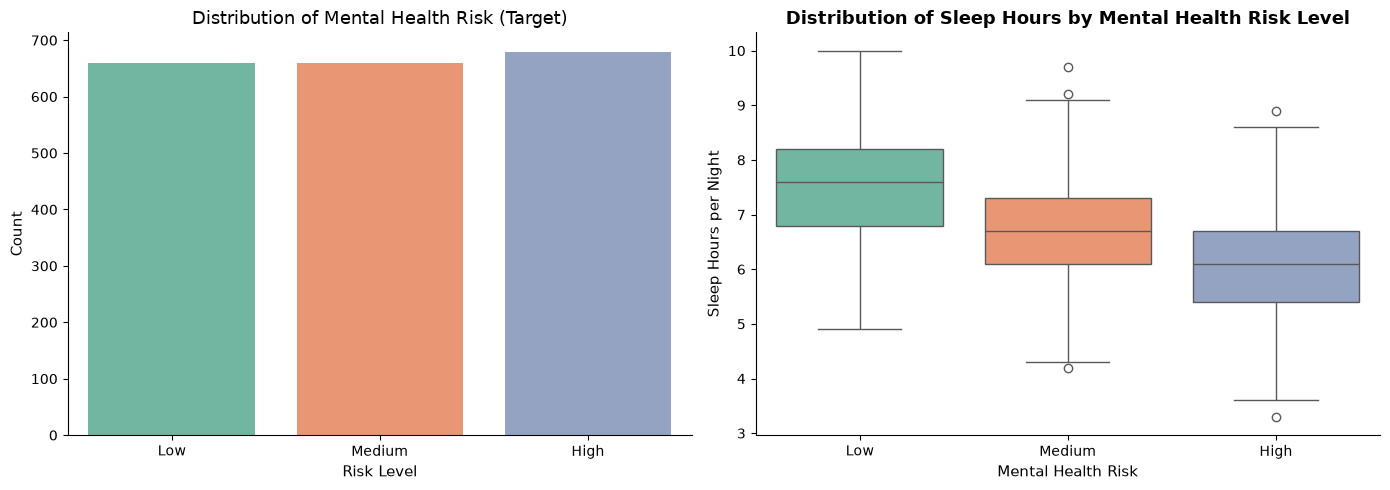

In [ ]:
# Étudier la distribution de la variable cible et l'éventuel déséquilibre des classes.
import seaborn as sns
figure, axis = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(
    data=data,
    x='Mental_Health_Risk',
    order=['Low', 'Medium', 'High'],
    palette='Set2',
    ax=axis[0]
)

axis[0].set_title('Distribution of Mental Health Risk (Target)', fontsize=13)
axis[0].set_xlabel('Risk Level', fontsize=11)
axis[0].set_ylabel('Count', fontsize=11)
sns.despine(ax=axis[0])

sns.boxplot(
    data=data,
    x='Mental_Health_Risk',
    y='Sleep_Hours',
    order=['Low', 'Medium', 'High'],
    palette='Set2',
    ax=axis[1] 
)

axis[1].set_title(
    'Distribution of Sleep Hours by Mental Health Risk Level',
    fontsize=13,
    fontweight='bold',
)
axis[1].set_xlabel('Mental Health Risk', fontsize=11)
axis[1].set_ylabel('Sleep Hours per Night', fontsize=11)
sns.despine(ax=axis[1])

plt.tight_layout()
plt.show()

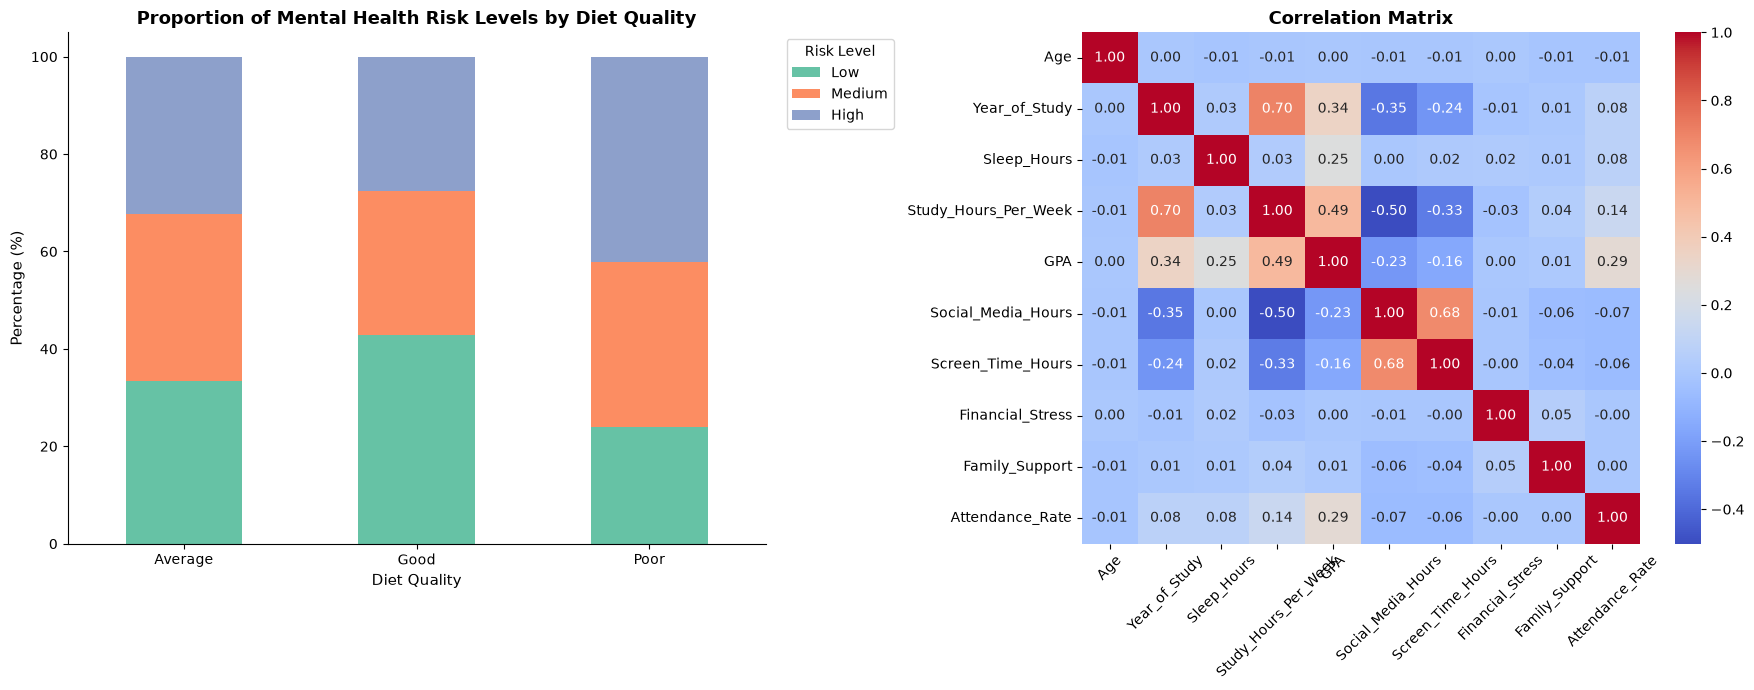

In [ ]:
diet_cross = pd.crosstab(
    data['Diet_Quality'],
    data['Mental_Health_Risk'],
    normalize='index'
) * 100

df_numeric = data.select_dtypes(include=['number'])
corr_matrix = df_numeric.corr()

figure, axis = plt.subplots(1, 2, figsize=(18, 7))
diet_cross[['Low', 'Medium', 'High']].plot(
    kind='bar',
    stacked=True,
    color=['#66c2a5', '#fc8d62', '#8da0cb'],
    ax=axis[0]
)

axis[0].set_title(
    'Proportion of Mental Health Risk Levels by Diet Quality',
    fontsize=13,
    fontweight='bold',
)
axis[0].set_xlabel('Diet Quality', fontsize=11)
axis[0].set_ylabel('Percentage (%)', fontsize=11)
axis[0].legend(title='Risk Level', bbox_to_anchor=(1.02, 1), loc='upper left')
axis[0].tick_params(axis='x', rotation=0)
sns.despine(ax=axis[0])

# --- Plot 2: Correlation heatmap ---
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    ax=axis[1],
)

axis[1].set_title('Correlation Matrix', fontsize=13, fontweight='bold')
axis[1].tick_params(axis='x', rotation=45)
axis[1].tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()

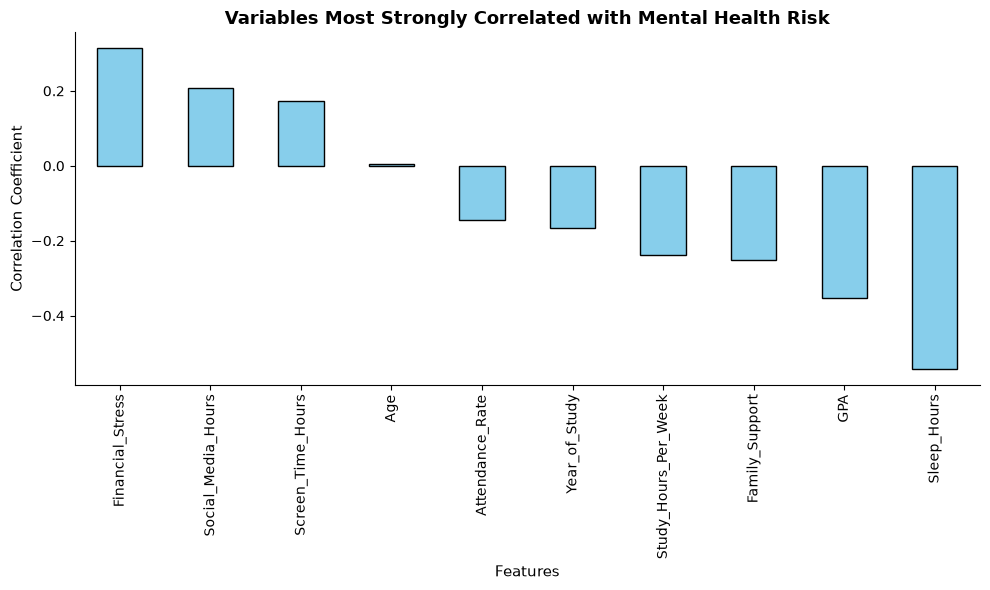

In [12]:
data_frame = data.copy()
risk_mapping = {
    'Low': 0,
    'Medium': 1,
    'High': 2
}
data_frame['Risk_numeric'] = data_frame['Mental_Health_Risk'].map(risk_mapping)

target_coor = (
    data_frame.select_dtypes(include=['number'])
    .corr()['Risk_numeric'].drop('Risk_numeric')
    .sort_values(ascending=False)
)

# print(target_coor)

plt.figure(figsize=(10, 6))
target_coor.plot(kind='bar', color='skyblue',edgecolor='black')
plt.title(
    'Variables Most Strongly Correlated with Mental Health Risk',
    fontsize=13,
    fontweight='bold',
)
plt.ylabel('Correlation Coefficient', fontsize=11)
plt.xlabel('Features', fontsize=11)
sns.despine()
plt.tight_layout()
plt.show()


In [13]:
import joblib
joblib.dump(data , "../data/01_data.joblib")

['../data/01_data.joblib']

In [4]:
data[data["Mental_Health_Risk"] == "Low"].head()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
6,STU0007,24,Male,2,7.7,15.0,2.77,8.8,10.2,Low,6.1,7.7,100.0,No,Good,No,Low
8,STU0009,20,Female,3,6.2,28.6,2.42,3.9,7.2,Moderate,5.3,8.4,72.6,No,Good,No,Low
17,STU0018,22,Male,4,8.8,25.4,2.76,6.0,9.9,Moderate,5.4,9.4,88.2,No,Poor,No,Low
23,STU0024,18,Female,3,6.3,19.6,2.41,5.6,6.8,Low,3.3,7.0,87.8,No,Poor,No,Low
31,STU0032,25,Female,3,8.7,12.9,2.98,5.0,7.5,Moderate,2.2,9.3,87.6,No,Good,No,Low
